In [1]:
###INDIRECT IMPACTS FREDDY

In [1]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd
import pickle

In [2]:
### impacts calculated
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/disrupt_imph2.pkl', 'rb') as file:
    disrupt_imph2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/disrupt_pp1.pkl', 'rb') as file:
    disrupt_pp1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/imph2.pkl', 'rb') as file:
    imph2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/imph1.pkl', 'rb') as file:
    imph1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/ed2.pkl', 'rb') as file:
    ed2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/rd2.pkl', 'rb') as file:
    rd2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/impp1.pkl', 'rb') as file:
    impp1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/impp2.pkl', 'rb') as file:
    impp2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/rd1_51ens.pkl', 'rb') as file:
    rd1_51ens = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/rd2_51ens.pkl', 'rb') as file:
    rd2_51ens = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/rd2_mimpact.pkl', 'rb') as file:
    rd2_mimpact = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/exp_dict.pkl', 'rb') as file:
    exp_dict = pickle.load(file)

In [3]:
##################### POPULATION 
from climada.entity.exposures.base import Exposures
#from climada.entity.exposures.base import Exposures
#Exposures.from_raster(path_cntry)
gdf_worldpop_MOZ = Exposures.from_raster('/cluster/work/climate/gespejo/data/infrastructure/population/moz_ppp_2020_1km_Aggregated_UNadj.tif')
#(exposure_pp.gdf.value==0).all()
#exposure_pp_MOZ.gdf
gdf_worldpop_MOZ.set_geometry_points()
###roads original
import geopandas as gpd
gdf_roads_MOZ = gpd.read_feather('/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ_2023/road')
# Rename the 'value' column to 'people'
## This one I should do anyway for the nex 
gdf_worldpop_MOZ.gdf.rename(columns={'value': 'people'}, inplace=True)

In [4]:
###SUBNATIONAL DIVISION 
import geopandas as gpd
geofile_MOZ = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)
from climada_petals.hazard.IMP_TRACKFORECAST import convert_to_geodf
gadm_MOZ_gdf = convert_to_geodf(gadm_MOZ, ['NAME_1', 'geometry'])

In [5]:
from climada_petals.hazard.IMP_Indirect import (
    get_disrupted_exposures_and_ensemble,
    get_disrupted_road,
    add_geometry_to_disrupted_roads,
    add_population_and_region_to_disrupted,
    cal_nearestpop_to_infrastructure,
    calc_pp_byroaddisrup_5ens,
    assign_province_to_roads)

In [6]:
def calculate_direct_and_indirect_impacts(
    imph2, imps2, impp1, rd2_mimpact,
    gdf_roads_MOZ,
    gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ
):
    # 1. Disrupted hospitals
    disrupted_hospitals = get_disrupted_exposures_and_ensemble(imph2, threshold=0.20, min_members=5, mode="above")
    disrupted_hospitals_copy = disrupted_hospitals.copy()
    
    # 2. Disrupted schools
    disrupted_schools = get_disrupted_exposures_and_ensemble(imps2, threshold=0.20, min_members=5, mode="above")
    disrupted_schools_copy = disrupted_schools.copy()
    
    # 3. Disrupted infrastructure (e.g. wind): add population + region
    impp1_disrupted = get_disrupted_exposures_and_ensemble(impp1, threshold=0.20, min_members=5, mode="above")
    impp1_disrupted = add_population_and_region_to_disrupted(impp1_disrupted, gdf_worldpop_MOZ.gdf, gadm_MOZ_gdf)
    impp1_disrupted_copy = impp1_disrupted.copy()
    
    # 4. Disrupted roads
    rd2_disrupted = get_disrupted_road(rd2_mimpact, threshold=0.20, min_members=5, mode="above")
    rd2_disrupted = add_geometry_to_disrupted_roads(rd2_disrupted, gdf_roads_MOZ)
    rd2_disrupted_copy = rd2_disrupted.copy()
    
    # 5. Indirect impacts
    imph2_impp1 = cal_nearestpop_to_infrastructure(disrupted_hospitals_copy, impp1_disrupted_copy)
    ed2_impp1 = cal_nearestpop_to_infrastructure(disrupted_schools_copy, impp1_disrupted_copy)
    rd2_disrupted_impp1 = calc_pp_byroaddisrup_5ens(rd2_disrupted_copy, impp1_disrupted_copy, radius_km=2)
    rd2_disrupted_impp1_copy =  rd2_disrupted_impp1.copy()
    rd2_disrupted_impp1 = assign_province_to_roads(rd2_disrupted_impp1_copy, gadm_MOZ)
    
    return imph2_impp1, ed2_impp1, impp1_disrupted_copy, rd2_disrupted_impp1

In [7]:
imph2_impp1_tsd020, ed2_impp1_tsd020, impp1_disrupted_tsd020, rd2_disrupted_impp1_tsd020 = calculate_direct_and_indirect_impacts(
    imph2, ed2, impp1, rd2_mimpact,
    gdf_roads_MOZ, gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ
)


 Starting nearest population match for 5 lead times...

  Processing: imph2_MOZ_new_Idai_20190310120000 | impp1_MOZ_Idai_20190310120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_Idai_20190310120000

  Processing: imph2_MOZ_new_Idai_20190311120000 | impp1_MOZ_Idai_20190311120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_Idai_20190311120000

  Processing: imph2_MOZ_new_Idai_20190312120000 | impp1_MOZ_Idai_20190312120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_Idai_20190312120000

  Processing: imph2_MOZ_new_Idai_20190313120000 | impp1_MOZ_Idai_20190313120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_Idai_20190313120000

  Processing: imph2_MOZ_new_Idai_20190314120000 | impp1_MOZ_Idai_20190314120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_Idai_20190314120000

 All processing complete.

 Starting nearest population match for 5 lead times...

  Processing: ed2_MOZ_new_Idai_20190310120000 | impp1_MOZ_Idai_2019031

In [8]:
# Save each dictionary separately to the specified directory
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/IDAI_picklefiles/'
with open(save_dir_pickle + 'imph2_impp1_tsd020.pkl', 'wb') as file:
    pickle.dump(imph2_impp1_tsd020, file)
with open(save_dir_pickle + 'ed2_impp1_tsd020.pkl', 'wb') as file:
    pickle.dump(ed2_impp1_tsd020, file)
with open(save_dir_pickle + 'impp1_disrupted_tsd020.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted_tsd020, file)
with open(save_dir_pickle + 'rd2_disrupted_impp1_tsd020.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted_impp1_tsd020, file)

In [ ]:
#### PLOTTING 

In [9]:
rename_dict = {
    'imph2_MOZ_new_Idai_20190310120000': '4 days',
    'imph2_MOZ_new_Idai_20190311120000': '3 days',
    'imph2_MOZ_new_Idai_20190312120000': '2 days',
    'imph2_MOZ_new_Idai_20190313120000': '1 day',
    'imph2_MOZ_new_Idai_20190314120000': 'landfall'
}
# Rename keys using rename_dict
imph2_impp1_tsd020 = {rename_dict.get(k, k): v for k, v in imph2_impp1_tsd020.items() if k in rename_dict}

In [10]:
rename_dict_impp1_disrupted = {
    'impp1_MOZ_Idai_20190310120000': '4 days',
    'impp1_MOZ_Idai_20190311120000': '3 days',
    'impp1_MOZ_Idai_20190312120000': '2 days',
    'impp1_MOZ_Idai_20190313120000': '1 day',
    'impp1_MOZ_Idai_20190314120000': 'landfall',
}
# Rename keys using rename_dict
impp1_disrupted_tsd020  = {rename_dict_impp1_disrupted.get(k, k): v for k, v in impp1_disrupted_tsd020.items() if k in rename_dict_impp1_disrupted}

In [11]:
###For schools 

In [12]:
rename_dict_ed2 = {
    'ed2_MOZ_new_Idai_20190310120000': '4 days',
    'ed2_MOZ_new_Idai_20190311120000': '3 days',
    'ed2_MOZ_new_Idai_20190312120000': '2 days',
    'ed2_MOZ_new_Idai_20190313120000': '1 day',
    'ed2_MOZ_new_Idai_20190314120000': 'landfall'
}
# Rename keys using rename_dict
ed2_impp1_tsd020 = {rename_dict_ed2.get(k, k): v for k, v in ed2_impp1_tsd020.items() if k in rename_dict_ed2}

In [13]:
###For roads

In [14]:
rename_dict_rd2 = {
    '20190310120000': '4 days',
    '20190311120000': '3 days',
    '20190312120000': '2 days',
    '20190313120000': '1 day',
    '20190314120000': 'landfall'
}
# Rename keys using rename_dict
rd2_disrupted_impp1_tsd020 = {rename_dict_rd2.get(k, k): v for k, v in rd2_disrupted_impp1_tsd020.items() if k in rename_dict_rd2}

In [15]:
rd2_disrupted_impp1_tsd020

{'4 days':            osm_id         0         1         2    3         4         5  \
 0      1004957067  0.018238  0.000000  0.113617  0.0  0.313298  0.356378   
 2      1005202159  0.000000  0.000000  0.019948  0.0  0.000000  0.337518   
 3      1005204545  0.115591  0.019390  0.251267  0.0  0.038492  0.020266   
 4      1005204821  0.000000  0.000000  0.020253  0.0  0.001283  0.338451   
 5      1005227301  0.019553  0.000000  0.306855  0.0  0.214825  0.403107   
 ...           ...       ...       ...       ...  ...       ...       ...   
 45660   990238041  0.238072  0.023929  0.303169  0.0  0.180253  0.021831   
 45661   991345635  0.341766  0.305841  0.326157  0.0  0.305805  0.037113   
 45662   991345636  0.341766  0.305841  0.326157  0.0  0.305805  0.037113   
 45663   998694067  0.000000  0.000000  0.156964  0.0  0.029877  0.393214   
 45664   998697326  0.000000  0.000000  0.156964  0.0  0.029877  0.393214   
 
               6         7    8  ...   46        47        48   

In [ ]:
## one by one 

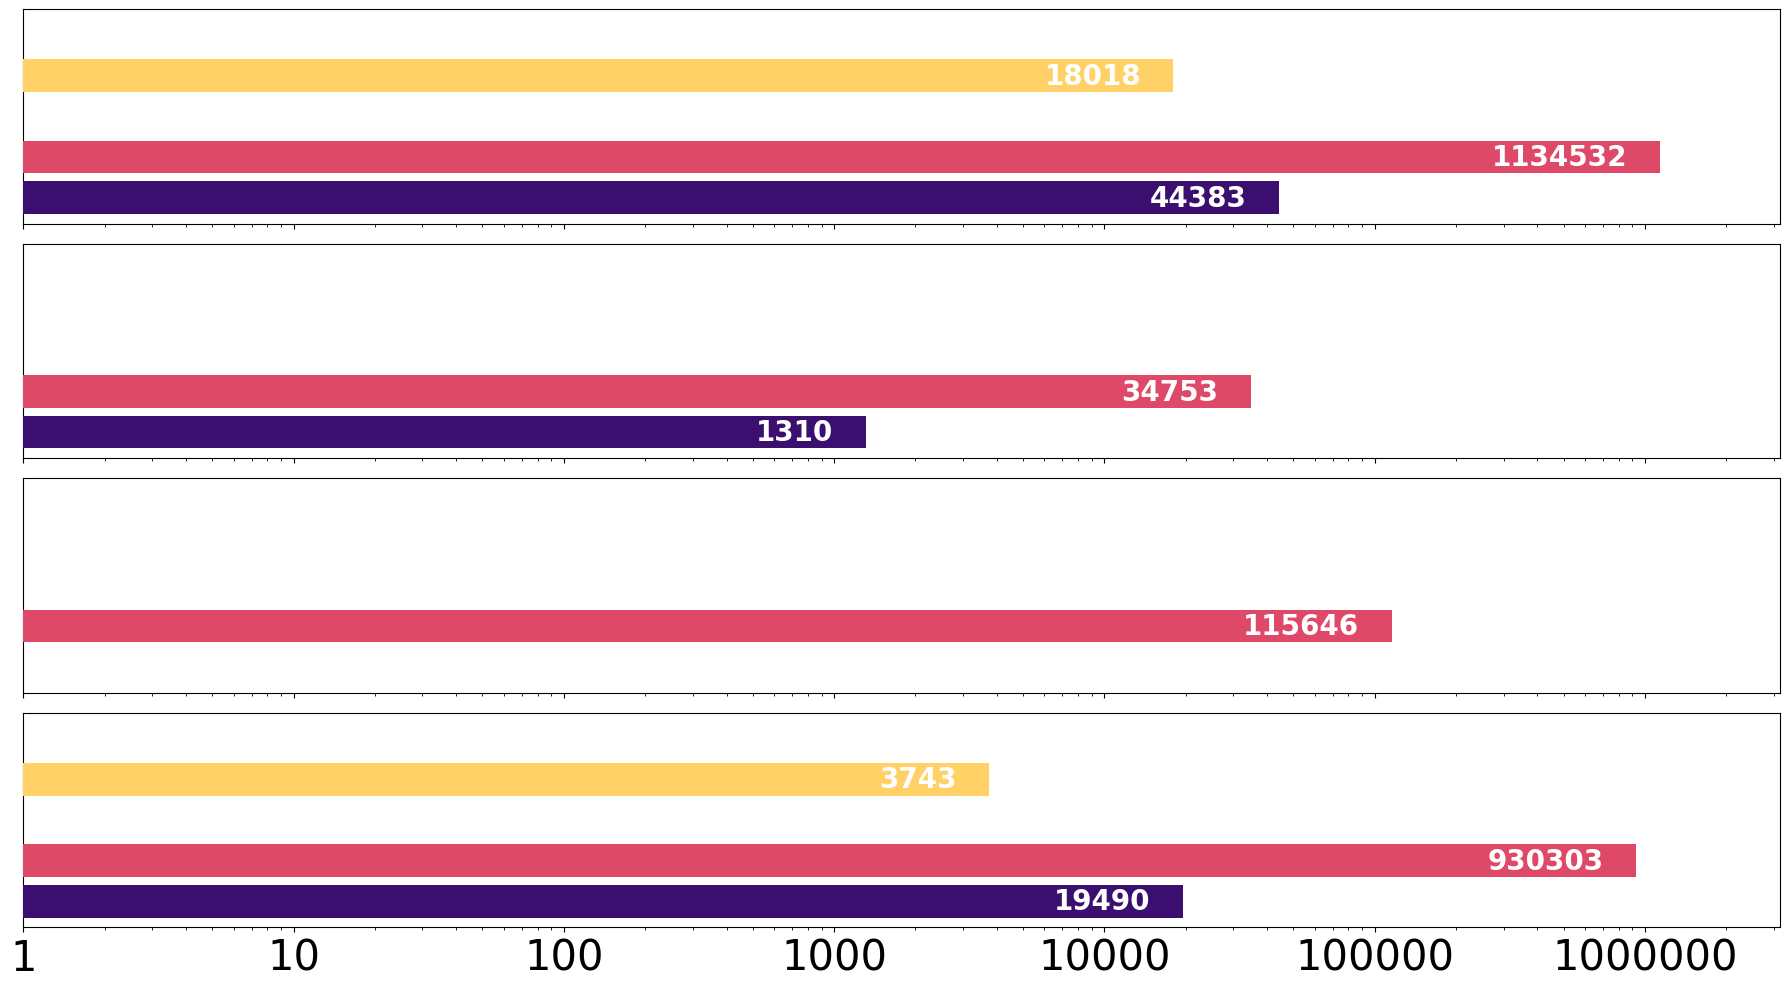

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

# ------------------- config -------------------
LEAD_TIME = '4 days'
X_MIN, X_MAX = 1, 1_000_000
RIGHT_PAD_DECADES = 0.5
X_MAX_PAD = X_MAX * (10**RIGHT_PAD_DECADES)

BAR_HEIGHT = 0.80
INSIDE_SHIFT_DECADES = 0.12      # how far left (in log10) to place label inside the bar
TICK_FONTSIZE = 30
LABEL_FONTSIZE = 20

province_colors = {
    'Zambezia':  '#3b0f70',  # deep purple
    'Sofala':    '#de4968',  # magenta/red
    'Nampula':   '#fe9f6d',  # orange
    'Inhambane': '#ffd166',  # yellow-orange
    'Manica':    '#06d6a0'   # teal
}
provinces = list(province_colors.keys())
# ----------------------------------------------

# ---------- helpers ----------
def fmt_plain(v):
    """Return an int with no separators (e.g., 1300, 1000000)."""
    try:
        return str(int(round(float(v))))
    except Exception:
        return str(v)

def _find_first_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def _sum_by_province_for_one_lead(obj_by_lt, lead_time, value_candidates):
    """Sum values by NAME_1 for a given lead_time from dict-of-DFs."""
    if isinstance(obj_by_lt, dict) and lead_time in obj_by_lt:
        df = obj_by_lt[lead_time]
        col = _find_first_col(df, value_candidates)
        if col is not None:
            s = df.groupby('NAME_1')[col].sum()
            return s.reindex(provinces).fillna(0.0)
    return pd.Series(0.0, index=provinces)

def _annotate_inside(ax, value, y):
    """Always draw the label INSIDE the bar, in white."""
    if value <= 0:
        return
    # place a bit left of the end in log space; clamp to axis range
    x_inside = value / (10**INSIDE_SHIFT_DECADES)
    x_inside = max(x_inside, X_MIN)           # keep within axis
    x_inside = min(x_inside, X_MAX_PAD*0.999) # safety
    ax.text(
        x_inside, y, fmt_plain(value),
        fontsize=LABEL_FONTSIZE, va='center', ha='right',
        color='white', weight='bold', clip_on=True, zorder=5
    )

# ---------- collect series (expects your dicts to exist) ----------
# impp1_disrupted_tsd020, imph2_impp1_tsd020, ed2_impp1_tsd020, rd2_disrupted_impp1_tsd020
s_p1  = _sum_by_province_for_one_lead(impp1_disrupted_tsd020,    LEAD_TIME,
                                      ['people','affected_pop','pp_affected','ind_pp_affected'])
s_h2  = _sum_by_province_for_one_lead(imph2_impp1_tsd020,         LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_ed2 = _sum_by_province_for_one_lead(ed2_impp1_tsd020,           LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_rd2 = _sum_by_province_for_one_lead(rd2_disrupted_impp1_tsd020, LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])

series_list = [
    ("Directly affected (Wind)",        s_p1),
    ("Indirectly affected (Hospital)",  s_h2),
    ("Indirectly affected (School)",    s_ed2),
    ("Indirectly affected (Road)",      s_rd2),
]

# -------------- plot --------------
plt.close('all')
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(18, 10), sharex=True)

for i, (title, s_vals) in enumerate(series_list):
    ax = axes[i]
    for k, prov in enumerate(provinces):
        v = float(s_vals.get(prov, 0.0))
        bar_val = max(v, X_MIN)  # avoid zero-length bars on log scale
        ax.barh(k, bar_val, color=province_colors[prov], height=BAR_HEIGHT, zorder=3)
        _annotate_inside(ax, v, k)

    ax.set_yticks([])
    ax.grid(False)
    ax.set_xscale('log')
    ax.set_xlim(X_MIN, X_MAX_PAD)

# shared x-axis: ticks and plain-integer labels (no commas/dots)
ticks = [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
for ax in axes:
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: fmt_plain(x)))
    ax.tick_params(axis='x', labelsize=TICK_FONTSIZE)

fig.tight_layout()
plt.savefig(
    "/cluster/home/gespejo/MOZ_struc_plots_Idai/direct_indirect_ppaff_4days.png",
    dpi=400, bbox_inches='tight'
)
plt.show()

In [ ]:
### for 3 days before 

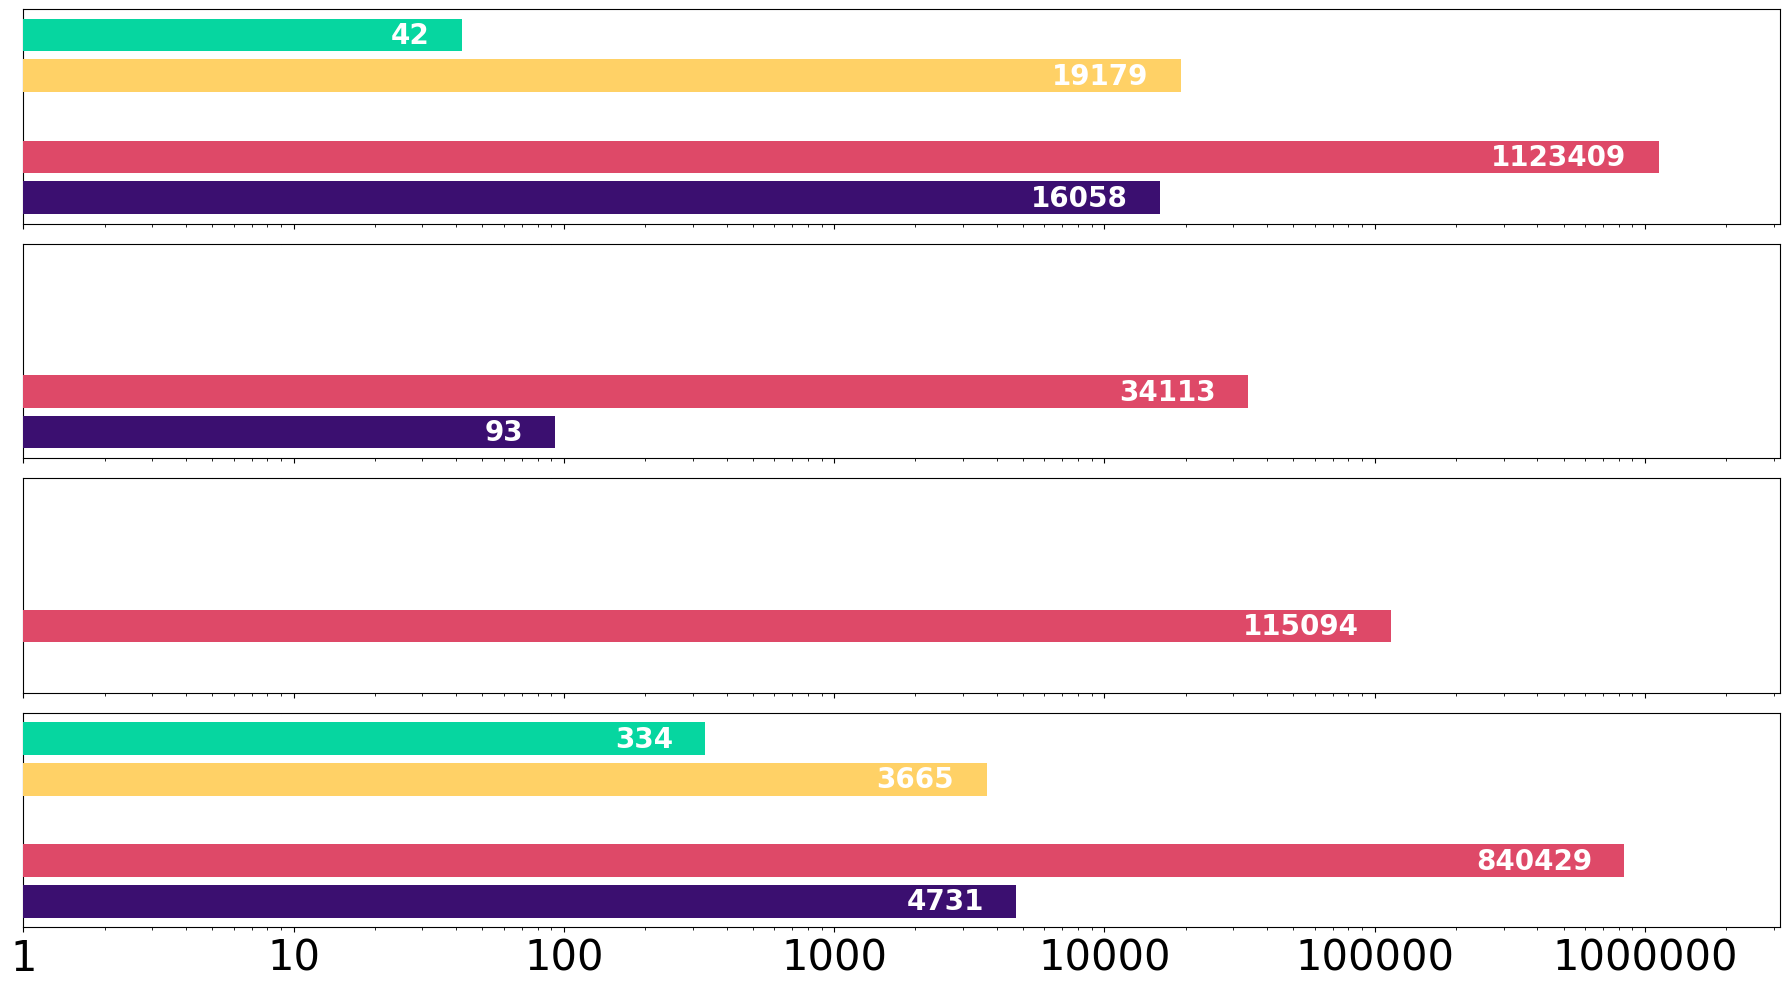

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

# ------------------- config -------------------
LEAD_TIME = '3 days'
X_MIN, X_MAX = 1, 1_000_000
RIGHT_PAD_DECADES = 0.5
X_MAX_PAD = X_MAX * (10**RIGHT_PAD_DECADES)

BAR_HEIGHT = 0.80
INSIDE_SHIFT_DECADES = 0.12      # how far left (in log10) to place label inside the bar
TICK_FONTSIZE = 30
LABEL_FONTSIZE = 20

province_colors = {
    'Zambezia':  '#3b0f70',  # deep purple
    'Sofala':    '#de4968',  # magenta/red
    'Nampula':   '#fe9f6d',  # orange
    'Inhambane': '#ffd166',  # yellow-orange
    'Manica':    '#06d6a0'   # teal
}
provinces = list(province_colors.keys())
# ----------------------------------------------

# ---------- helpers ----------
def fmt_plain(v):
    """Return an int with no separators (e.g., 1300, 1000000)."""
    try:
        return str(int(round(float(v))))
    except Exception:
        return str(v)

def _find_first_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def _sum_by_province_for_one_lead(obj_by_lt, lead_time, value_candidates):
    """Sum values by NAME_1 for a given lead_time from dict-of-DFs."""
    if isinstance(obj_by_lt, dict) and lead_time in obj_by_lt:
        df = obj_by_lt[lead_time]
        col = _find_first_col(df, value_candidates)
        if col is not None:
            s = df.groupby('NAME_1')[col].sum()
            return s.reindex(provinces).fillna(0.0)
    return pd.Series(0.0, index=provinces)

def _annotate_inside(ax, value, y):
    """Always draw the label INSIDE the bar, in white."""
    if value <= 0:
        return
    # place a bit left of the end in log space; clamp to axis range
    x_inside = value / (10**INSIDE_SHIFT_DECADES)
    x_inside = max(x_inside, X_MIN)           # keep within axis
    x_inside = min(x_inside, X_MAX_PAD*0.999) # safety
    ax.text(
        x_inside, y, fmt_plain(value),
        fontsize=LABEL_FONTSIZE, va='center', ha='right',
        color='white', weight='bold', clip_on=True, zorder=5
    )

# ---------- collect series (expects your dicts to exist) ----------
# impp1_disrupted_tsd020, imph2_impp1_tsd020, ed2_impp1_tsd020, rd2_disrupted_impp1_tsd020
s_p1  = _sum_by_province_for_one_lead(impp1_disrupted_tsd020,    LEAD_TIME,
                                      ['people','affected_pop','pp_affected','ind_pp_affected'])
s_h2  = _sum_by_province_for_one_lead(imph2_impp1_tsd020,         LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_ed2 = _sum_by_province_for_one_lead(ed2_impp1_tsd020,           LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_rd2 = _sum_by_province_for_one_lead(rd2_disrupted_impp1_tsd020, LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])

series_list = [
    ("Directly affected (Wind)",        s_p1),
    ("Indirectly affected (Hospital)",  s_h2),
    ("Indirectly affected (School)",    s_ed2),
    ("Indirectly affected (Road)",      s_rd2),
]

# -------------- plot --------------
plt.close('all')
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(18, 10), sharex=True)

for i, (title, s_vals) in enumerate(series_list):
    ax = axes[i]
    for k, prov in enumerate(provinces):
        v = float(s_vals.get(prov, 0.0))
        bar_val = max(v, X_MIN)  # avoid zero-length bars on log scale
        ax.barh(k, bar_val, color=province_colors[prov], height=BAR_HEIGHT, zorder=3)
        _annotate_inside(ax, v, k)

    ax.set_yticks([])
    ax.grid(False)
    ax.set_xscale('log')
    ax.set_xlim(X_MIN, X_MAX_PAD)

# shared x-axis: ticks and plain-integer labels (no commas/dots)
ticks = [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
for ax in axes:
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: fmt_plain(x)))
    ax.tick_params(axis='x', labelsize=TICK_FONTSIZE)

fig.tight_layout()
plt.savefig(
    "/cluster/home/gespejo/MOZ_struc_plots_Idai/direct_indirect_ppaff_3days.png",
    dpi=400, bbox_inches='tight'
)
plt.show()

In [ ]:
###for 2 days 

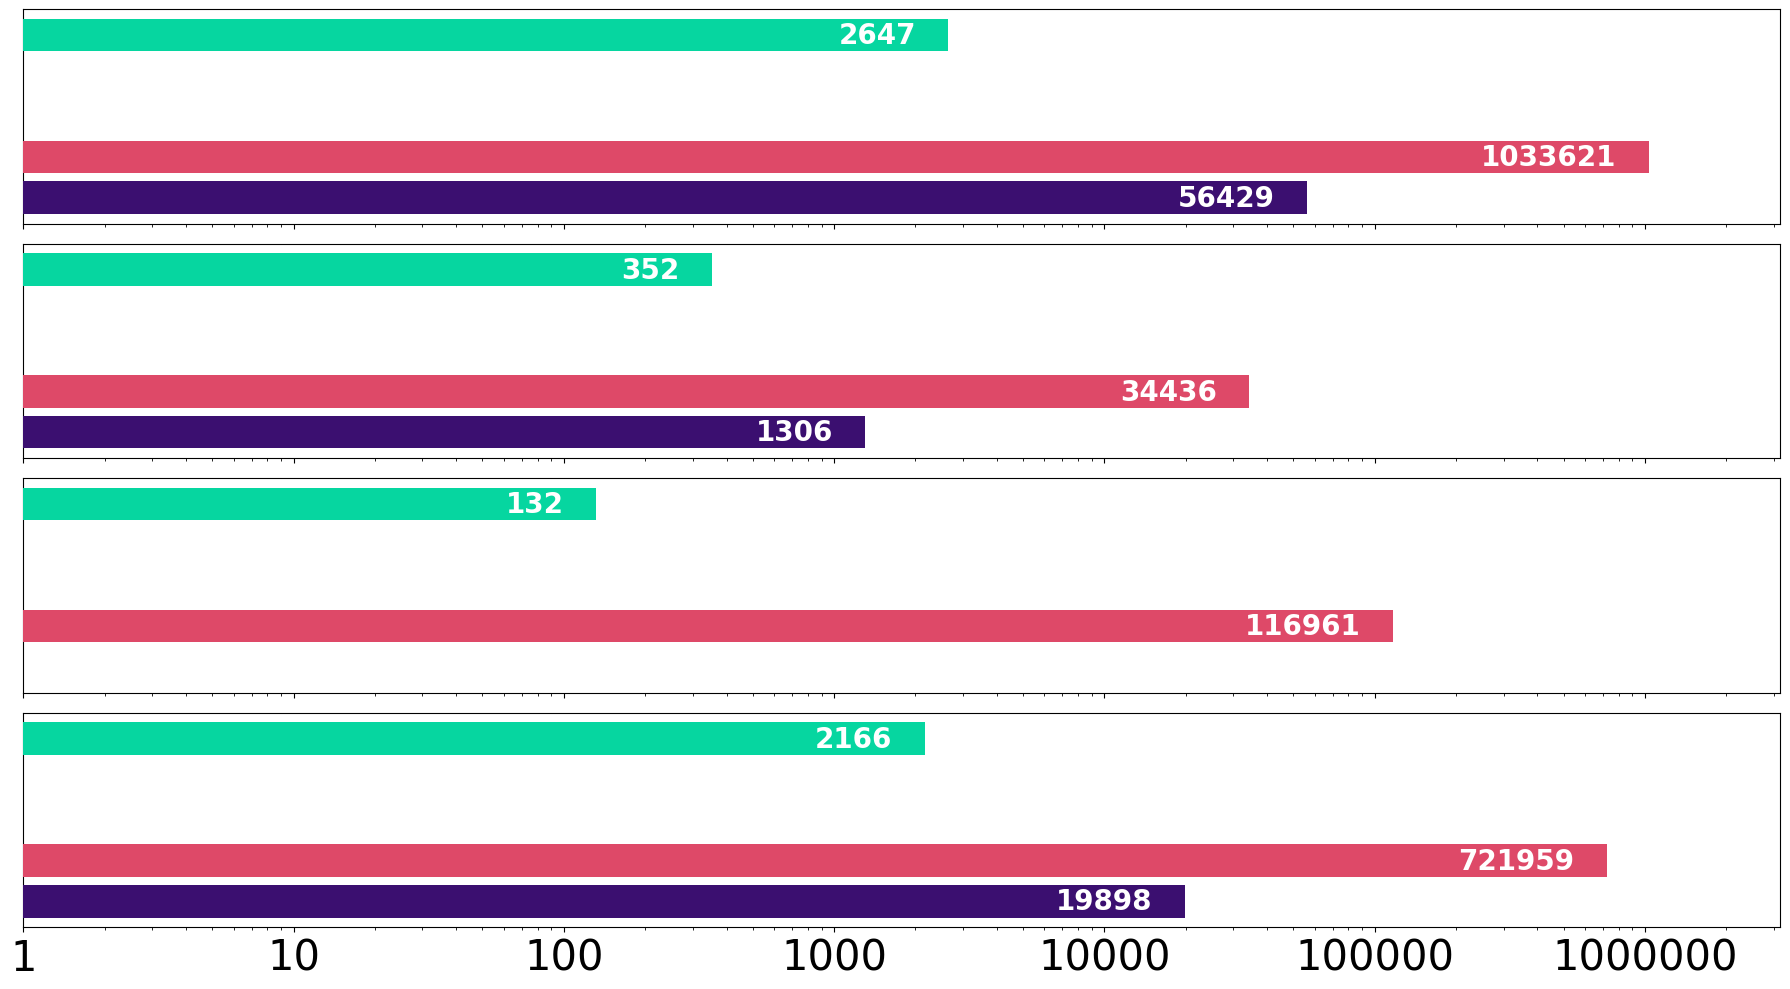

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

# ------------------- config -------------------
LEAD_TIME = '2 days'
X_MIN, X_MAX = 1, 1_000_000
RIGHT_PAD_DECADES = 0.5
X_MAX_PAD = X_MAX * (10**RIGHT_PAD_DECADES)

BAR_HEIGHT = 0.80
INSIDE_SHIFT_DECADES = 0.12      # how far left (in log10) to place label inside the bar
TICK_FONTSIZE = 30
LABEL_FONTSIZE = 20

province_colors = {
    'Zambezia':  '#3b0f70',  # deep purple
    'Sofala':    '#de4968',  # magenta/red
    'Nampula':   '#fe9f6d',  # orange
    'Inhambane': '#ffd166',  # yellow-orange
    'Manica':    '#06d6a0'   # teal
}
provinces = list(province_colors.keys())
# ----------------------------------------------

# ---------- helpers ----------
def fmt_plain(v):
    """Return an int with no separators (e.g., 1300, 1000000)."""
    try:
        return str(int(round(float(v))))
    except Exception:
        return str(v)

def _find_first_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def _sum_by_province_for_one_lead(obj_by_lt, lead_time, value_candidates):
    """Sum values by NAME_1 for a given lead_time from dict-of-DFs."""
    if isinstance(obj_by_lt, dict) and lead_time in obj_by_lt:
        df = obj_by_lt[lead_time]
        col = _find_first_col(df, value_candidates)
        if col is not None:
            s = df.groupby('NAME_1')[col].sum()
            return s.reindex(provinces).fillna(0.0)
    return pd.Series(0.0, index=provinces)

def _annotate_inside(ax, value, y):
    """Always draw the label INSIDE the bar, in white."""
    if value <= 0:
        return
    # place a bit left of the end in log space; clamp to axis range
    x_inside = value / (10**INSIDE_SHIFT_DECADES)
    x_inside = max(x_inside, X_MIN)           # keep within axis
    x_inside = min(x_inside, X_MAX_PAD*0.999) # safety
    ax.text(
        x_inside, y, fmt_plain(value),
        fontsize=LABEL_FONTSIZE, va='center', ha='right',
        color='white', weight='bold', clip_on=True, zorder=5
    )

# ---------- collect series (expects your dicts to exist) ----------
# impp1_disrupted_tsd020, imph2_impp1_tsd020, ed2_impp1_tsd020, rd2_disrupted_impp1_tsd020
s_p1  = _sum_by_province_for_one_lead(impp1_disrupted_tsd020,    LEAD_TIME,
                                      ['people','affected_pop','pp_affected','ind_pp_affected'])
s_h2  = _sum_by_province_for_one_lead(imph2_impp1_tsd020,         LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_ed2 = _sum_by_province_for_one_lead(ed2_impp1_tsd020,           LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_rd2 = _sum_by_province_for_one_lead(rd2_disrupted_impp1_tsd020, LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])

series_list = [
    ("Directly affected (Wind)",        s_p1),
    ("Indirectly affected (Hospital)",  s_h2),
    ("Indirectly affected (School)",    s_ed2),
    ("Indirectly affected (Road)",      s_rd2),
]

# -------------- plot --------------
plt.close('all')
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(18, 10), sharex=True)

for i, (title, s_vals) in enumerate(series_list):
    ax = axes[i]
    for k, prov in enumerate(provinces):
        v = float(s_vals.get(prov, 0.0))
        bar_val = max(v, X_MIN)  # avoid zero-length bars on log scale
        ax.barh(k, bar_val, color=province_colors[prov], height=BAR_HEIGHT, zorder=3)
        _annotate_inside(ax, v, k)

    ax.set_yticks([])
    ax.grid(False)
    ax.set_xscale('log')
    ax.set_xlim(X_MIN, X_MAX_PAD)

# shared x-axis: ticks and plain-integer labels (no commas/dots)
ticks = [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
for ax in axes:
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: fmt_plain(x)))
    ax.tick_params(axis='x', labelsize=TICK_FONTSIZE)

fig.tight_layout()
plt.savefig(
    "/cluster/home/gespejo/MOZ_struc_plots_Idai/direct_indirect_ppaff_2days.png",
    dpi=400, bbox_inches='tight'
)
plt.show()

In [ ]:
### for 1 day before 

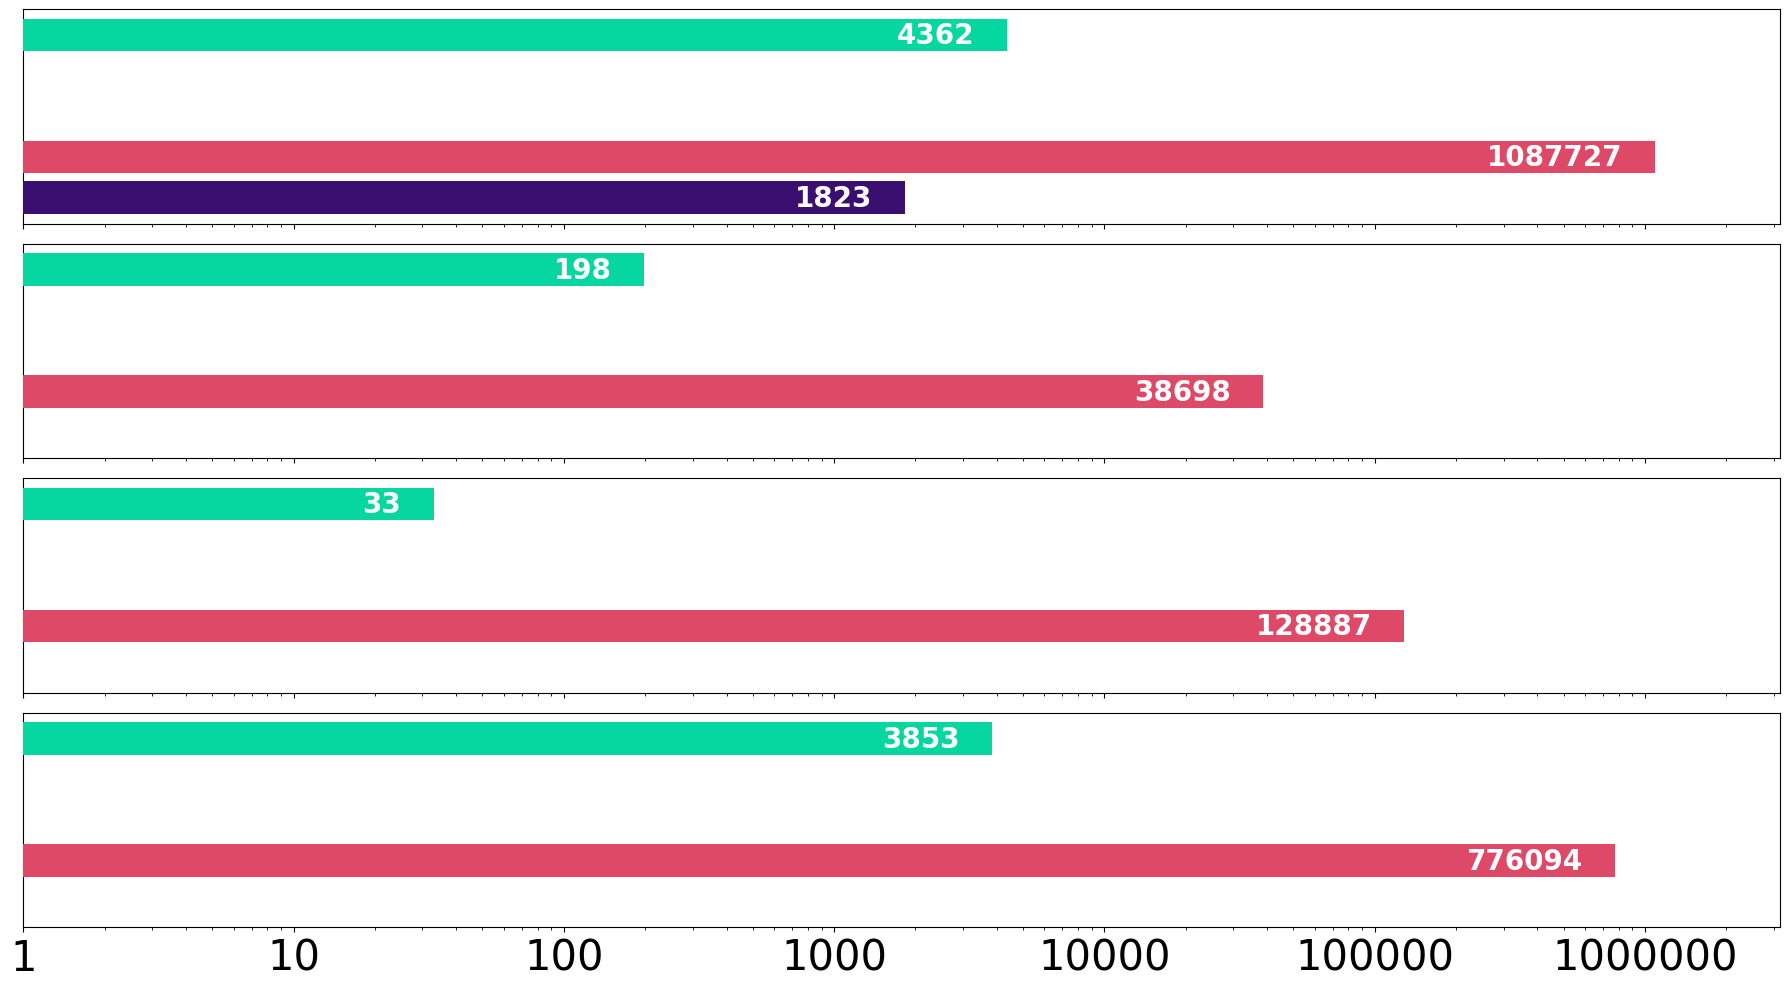

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

# ------------------- config -------------------
LEAD_TIME = '1 day'
X_MIN, X_MAX = 1, 1_000_000
RIGHT_PAD_DECADES = 0.5
X_MAX_PAD = X_MAX * (10**RIGHT_PAD_DECADES)

BAR_HEIGHT = 0.80
INSIDE_SHIFT_DECADES = 0.12      # how far left (in log10) to place label inside the bar
TICK_FONTSIZE = 30
LABEL_FONTSIZE = 20

province_colors = {
    'Zambezia':  '#3b0f70',  # deep purple
    'Sofala':    '#de4968',  # magenta/red
    'Nampula':   '#fe9f6d',  # orange
    'Inhambane': '#ffd166',  # yellow-orange
    'Manica':    '#06d6a0'   # teal
}
provinces = list(province_colors.keys())
# ----------------------------------------------

# ---------- helpers ----------
def fmt_plain(v):
    """Return an int with no separators (e.g., 1300, 1000000)."""
    try:
        return str(int(round(float(v))))
    except Exception:
        return str(v)

def _find_first_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def _sum_by_province_for_one_lead(obj_by_lt, lead_time, value_candidates):
    """Sum values by NAME_1 for a given lead_time from dict-of-DFs."""
    if isinstance(obj_by_lt, dict) and lead_time in obj_by_lt:
        df = obj_by_lt[lead_time]
        col = _find_first_col(df, value_candidates)
        if col is not None:
            s = df.groupby('NAME_1')[col].sum()
            return s.reindex(provinces).fillna(0.0)
    return pd.Series(0.0, index=provinces)

def _annotate_inside(ax, value, y):
    """Always draw the label INSIDE the bar, in white."""
    if value <= 0:
        return
    # place a bit left of the end in log space; clamp to axis range
    x_inside = value / (10**INSIDE_SHIFT_DECADES)
    x_inside = max(x_inside, X_MIN)           # keep within axis
    x_inside = min(x_inside, X_MAX_PAD*0.999) # safety
    ax.text(
        x_inside, y, fmt_plain(value),
        fontsize=LABEL_FONTSIZE, va='center', ha='right',
        color='white', weight='bold', clip_on=True, zorder=5
    )

# ---------- collect series (expects your dicts to exist) ----------
# impp1_disrupted_tsd020, imph2_impp1_tsd020, ed2_impp1_tsd020, rd2_disrupted_impp1_tsd020
s_p1  = _sum_by_province_for_one_lead(impp1_disrupted_tsd020,    LEAD_TIME,
                                      ['people','affected_pop','pp_affected','ind_pp_affected'])
s_h2  = _sum_by_province_for_one_lead(imph2_impp1_tsd020,         LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_ed2 = _sum_by_province_for_one_lead(ed2_impp1_tsd020,           LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])
s_rd2 = _sum_by_province_for_one_lead(rd2_disrupted_impp1_tsd020, LEAD_TIME,
                                      ['pp_affected','ind_pp_affected','affected_pop'])

series_list = [
    ("Directly affected (Wind)",        s_p1),
    ("Indirectly affected (Hospital)",  s_h2),
    ("Indirectly affected (School)",    s_ed2),
    ("Indirectly affected (Road)",      s_rd2),
]

# -------------- plot --------------
plt.close('all')
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(18, 10), sharex=True)

for i, (title, s_vals) in enumerate(series_list):
    ax = axes[i]
    for k, prov in enumerate(provinces):
        v = float(s_vals.get(prov, 0.0))
        bar_val = max(v, X_MIN)  # avoid zero-length bars on log scale
        ax.barh(k, bar_val, color=province_colors[prov], height=BAR_HEIGHT, zorder=3)
        _annotate_inside(ax, v, k)

    ax.set_yticks([])
    ax.grid(False)
    ax.set_xscale('log')
    ax.set_xlim(X_MIN, X_MAX_PAD)

# shared x-axis: ticks and plain-integer labels (no commas/dots)
ticks = [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
for ax in axes:
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: fmt_plain(x)))
    ax.tick_params(axis='x', labelsize=TICK_FONTSIZE)

fig.tight_layout()
plt.savefig(
    "/cluster/home/gespejo/MOZ_struc_plots_Idai/direct_indirect_ppaff_1day.png",
    dpi=400, bbox_inches='tight'
)
plt.show()

In [ ]:
### Entire plot 

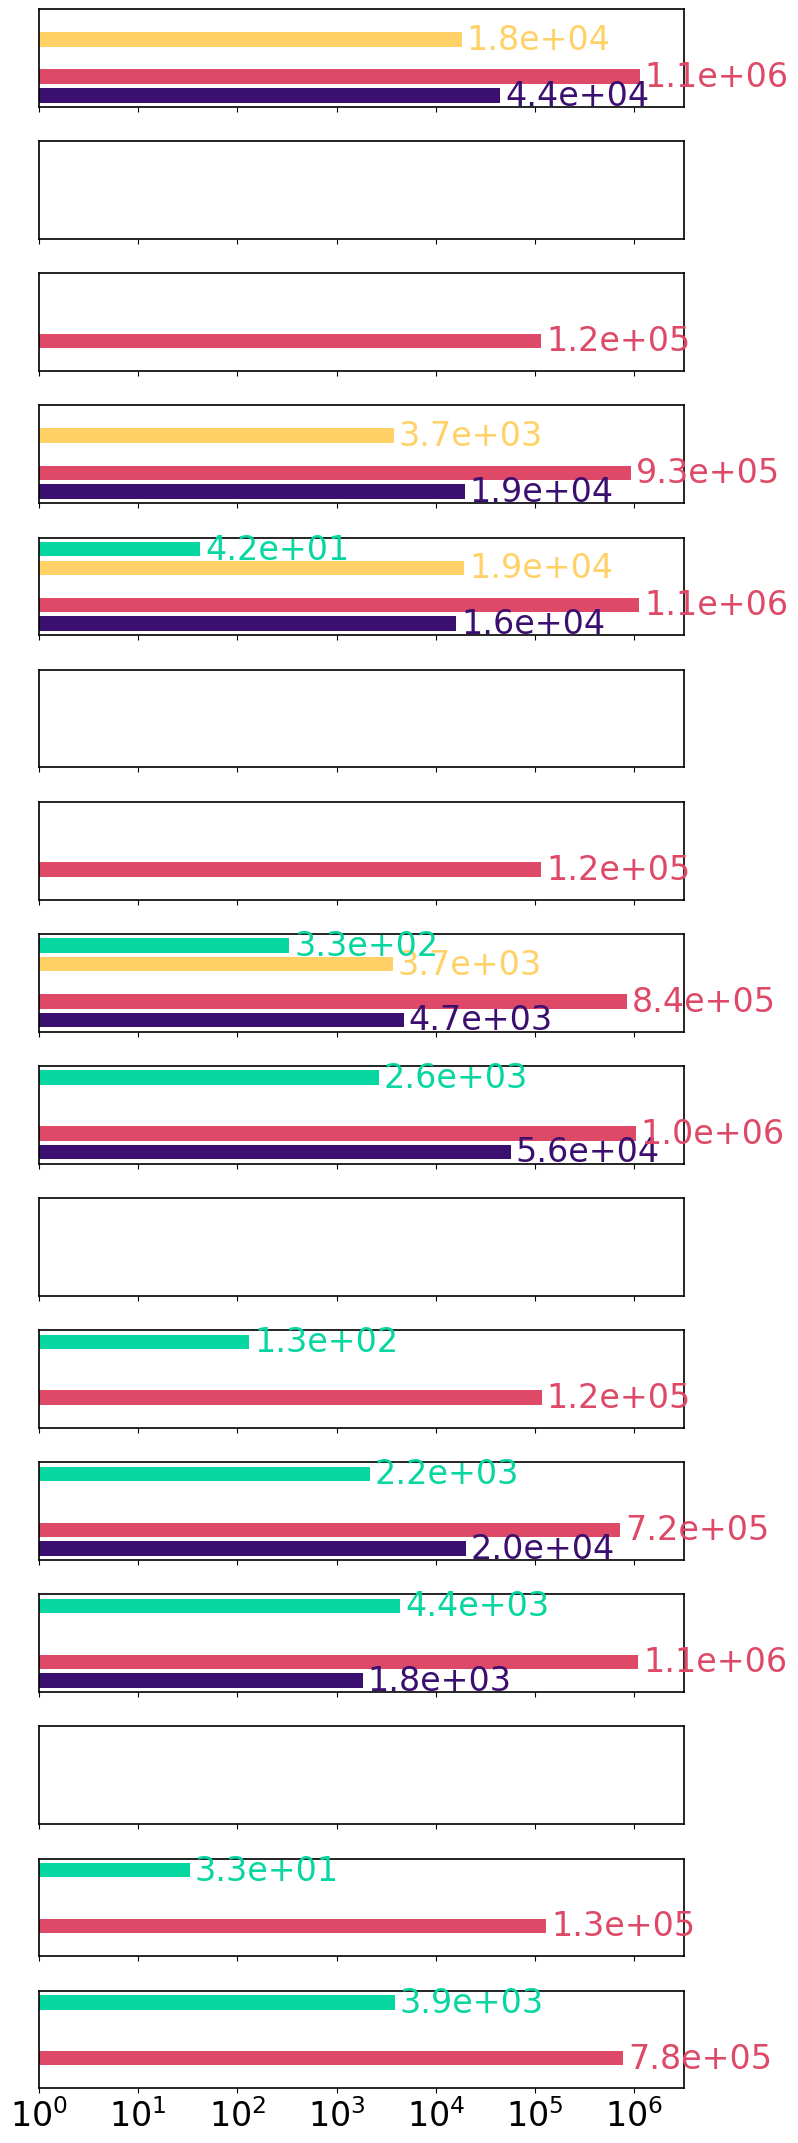

In [54]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FixedLocator, LogFormatterMathtext

# ---------------- CONFIG (tweak here) ----------------
lead_times = ['4 days', '3 days', '2 days', '1 day']

X_MIN, X_MAX = 1, 1_000_000
X_MAX_PAD = X_MAX * (10**0.5)  # extend to 10^6.5 for breathing room

province_colors = {
    'Zambezia':  '#3b0f70',  # deep purple
    'Sofala':    '#de4968',  # magenta/red
    'Nampula':   '#fe9f6d',  # orange
    'Inhambane': '#ffd166',  # yellow-orange
    'Manica':    '#06d6a0'   # teal
}
provinces = list(province_colors.keys())

# Publication sizing
FIG_WIDTH_IN      = 7.5     # ~page width; raise to 8.5–9.0 if you prefer wider
ROW_HEIGHT_IN     = 1.35    # height per row; increase for more vertical space
BAR_HEIGHT        = 0.78    # thicker bars for print
ANNOT_FONTSIZE    = 24
TICK_FONTSIZE     = 24
DAYLABEL_FONTSIZE = 26
SPINE_LW          = 1.2
DPI_SAVE          = 800     # hi-DPI PNG; also save vector copies below

plt.close('all')

# ---------------- HELPERS ----------------
def _find_first_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def _sum_by_province_for_one_lead(obj_by_lt, lead_time, value_candidates):
    """Series (index=provinces) with sums at the given lead_time."""
    if isinstance(obj_by_lt, dict) and lead_time in obj_by_lt:
        df = obj_by_lt[lead_time]
        col = _find_first_col(df, value_candidates)
        if col is None:
            s = pd.Series(0.0, index=provinces)
        else:
            s = df.groupby('NAME_1')[col].sum().reindex(provinces).fillna(0.0)
    else:
        s = pd.Series(0.0, index=provinces)
    return s

def _annotate_bar(ax, value, y, color):
    if value <= 0:
        return
    # keep label safely inside padded limit and bump size
    ax.text(min(value*1.12, X_MAX_PAD*0.96), y, f"{value:.1e}",
            fontsize=ANNOT_FONTSIZE, va='center', ha='left', color=color)

# ---------------- BUILD ALL SERIES (by day) ----------------
day_blocks = []  # each item: [direct, hosp, school, road] for that day

for lt in lead_times:
    s_direct = _sum_by_province_for_one_lead(
        impp1_disrupted, lt, ['people','affected_pop','pp_affected','ind_pp_affected']
    )
    s_hosp   = _sum_by_province_for_one_lead(
        imph2_impp1, lt,   ['pp_affected','ind_pp_affected','affected_pop']
    )
    s_school = _sum_by_province_for_one_lead(
        ed2_impp1, lt,     ['pp_affected','ind_pp_affected','affected_pop']
    )
    s_road   = _sum_by_province_for_one_lead(
        rd2_disrupted_impp1, lt, ['pp_affected','ind_pp_affected','affected_pop']
    )
    day_blocks.append([s_direct, s_hosp, s_school, s_road])

# ---------------- PLOT (single column, shared x) ----------------
n_rows = len(lead_times) * 4
fig_height = ROW_HEIGHT_IN * n_rows + 1.25  # a little bottom margin
fig, axes = plt.subplots(nrows=n_rows, ncols=1,
                         figsize=(FIG_WIDTH_IN, fig_height),
                         sharex=True)

row_idx = 0
for day_i, lt in enumerate(lead_times):
    series_list = day_blocks[day_i]  # [direct, hosp, school, road]
    for s_vals in series_list:
        ax = axes[row_idx]

        # thicker spines for print
        for side in ("bottom", "left", "right", "top"):
            ax.spines[side].set_linewidth(SPINE_LW)

        # horizontal bars per province
        for k, prov in enumerate(provinces):
            v = float(s_vals.get(prov, 0.0))
            ax.barh(k, max(v, X_MIN), color=province_colors[prov], height=BAR_HEIGHT)
            if v > 0:
                _annotate_bar(ax, v, k, province_colors[prov])

        ax.set_yticks([])               # legend-free minimalist look
        ax.tick_params(axis='y', length=0)
        ax.grid(False)
        ax.tick_params(axis='x', labelsize=TICK_FONTSIZE)

        # hide x tick labels except on the last row
        if row_idx < n_rows - 1:
            ax.tick_params(axis='x', which='both', labelbottom=False)

        row_idx += 1

    # add the day tag to the left of the top row of this block
    #top_ax = axes[row_idx - 4]
    #top_ax.text(-0.08, 1.08, lt, transform=top_ax.transAxes,
    #            fontsize=DAYLABEL_FONTSIZE, va='bottom', ha='left', fontweight='bold')

# shared log x: decades + padded limit to 10^6.5
decade_ticks = [10**k for k in range(0, 7)]  # 10^0..10^6
for ax in axes:
    ax.set_xscale('log')
    ax.set_xlim(X_MIN, X_MAX_PAD)
    ax.xaxis.set_major_locator(FixedLocator(decade_ticks))
    ax.xaxis.set_major_formatter(LogFormatterMathtext())

# bottom label only (shared axis)
axes[-1].set_xlabel("", fontsize=TICK_FONTSIZE+2, labelpad=8)

plt.subplots_adjust(left=0.12, right=0.98, top=0.98, bottom=0.07, hspace=0.35)
fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Idai/direct_indirect_people_all_days_singlecolumn.png",
             dpi=800, bbox_inches='tight')
plt.show()

In [47]:
## PLOTTING one by one 

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Province colors (same as in main plot)
province_colors = {
    'Zambezia':  '#3b0f70',  # deep purple
    'Sofala':    '#de4968',  # magenta/red
    'Nampula':   '#fe9f6d',  # orange
    'Inhambane': '#ffd166',  # yellow-orange
    'Manica':    '#06d6a0'   # teal
}

# Create legend handles
legend_handles = [Patch(color=color, label=province) for province, color in province_colors.items()]

# Create standalone legend figure
fig_legend = plt.figure(figsize=(4, 1))  # Adjust size as needed
plt.legend(handles=legend_handles, loc='center', ncol=len(province_colors),
           title='Province', title_fontsize=14, fontsize=12, frameon=False)

# Remove axes
plt.axis('off')

# Save the legend
plt.savefig("/cluster/home/gespejo/MOZ_struc_plots_Idai/legend_provinces.png",
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
###ADDITIONAL STEPS 